# 02 - Baseline models and validation for FD001

**Purpose:** build simple baselines, validate them honestly, and use the results to make
evidence-based choices (model, feature set, RUL cap).

**Validation design (read this first):**
- Cross-validation is **grouped by engine**: an engine is either in the training part or the
  validation part of a fold, never both.
- The 100 **test engines are not touched** until the final section, and only once.
- Scalers are fitted inside each fold (they live in a Pipeline), so no information leaks from
  validation engines.
- Metrics: RMSE and MAE (cycles) and the asymmetric PHM08 score (late predictions penalised more).

Cells marked **Your observation** are for you to complete.

## 1. Setup

In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent))

from src.data_loader import add_rul, load_fd001
from src.evaluation import cross_validate, mae, nasa_score, rmse
from src.features import DROPPED_SENSORS, get_feature_columns, last_rows
from src.models import baseline_models

train, test, rul_test = load_fd001()
train = add_rul(train)  # uncapped RUL; capping is applied inside cross_validate

CAP = 125               # starting value; tested in section 4
FEATURES = get_feature_columns()
print(len(FEATURES), "features:", FEATURES)

14 features: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 2. Compare the baseline models (5-fold grouped CV)

In [10]:
def summarise(result):
    """Mean and std across folds for one cross_validate result."""
    out = {}
    for col in ["rmse", "mae", "nasa_score", "fit_s", "predict_s"]:
        out[col] = result[col].mean()
        out[col + "_std"] = result[col].std()
    return out

models = baseline_models()
rows = {}
for name, factory in models.items():
    rows[name] = summarise(cross_validate(factory, train, FEATURES, cap=CAP))
comparison = pd.DataFrame(rows).T
comparison[["rmse", "rmse_std", "mae", "nasa_score", "fit_s", "predict_s"]].round(3)

,rmse,rmse_std,mae,nasa_score,fit_s,predict_s
mean,41.673,0.004,36.965,1271029.338,0.002,0.000
ridge,21.657,1.544,17.745,40023.308,0.013,0.001
random_forest,18.874,0.685,13.769,58386.725,5.489,0.064
hist_gradient_boosting,18.731,0.624,13.486,60178.554,0.459,0.009


**Your observation:** How much better than the "mean" baseline is each model? Is the gap between
models larger than the fold-to-fold spread (the `rmse_std` column)? What do fit and predict times
suggest about cost? Which model would you carry forward, and why?

## 3. Does the feature set matter? (sensor ablation)

Sections 3 and 4 repeat cross-validation many times, so they use the fast models (ridge and
gradient boosting). Random forest took much longer to fit in section 2; if you carry it forward,
re-run a few key rows with it.

In [11]:
feature_sets = {
    "default (14 sensors)": get_feature_columns(),
    "+ settings": get_feature_columns(include_settings=True),
    "without sensors 9, 14": get_feature_columns(DROPPED_SENSORS + ["sensor_9", "sensor_14"]),
    "without 9, 14 and noisy 8, 13, 17": get_feature_columns(
        DROPPED_SENSORS + ["sensor_9", "sensor_14", "sensor_8", "sensor_13", "sensor_17"]),
}
abl_rows = []
for fs_name, cols in feature_sets.items():
    for model_name in ["ridge", "hist_gradient_boosting"]:
        res = cross_validate(models[model_name], train, cols, cap=CAP)
        abl_rows.append({"features": fs_name, "model": model_name, "n_features": len(cols),
                         "rmse": res["rmse"].mean(), "rmse_std": res["rmse"].std()})
ablation = pd.DataFrame(abl_rows).round(3)
ablation

,features,model,n_features,rmse,rmse_std
0,default (14 sensors),ridge,14,21.657,1.544
1,default (14 sensors),hist_gradient_boosting,14,18.731,0.624
2,+ settings,ridge,17,21.660,1.546
3,+ settings,hist_gradient_boosting,17,18.712,0.669
4,"without sensors 9, 14",ridge,12,22.900,1.630
5,"without sensors 9, 14",hist_gradient_boosting,12,21.168,1.140
6,"without 9, 14 and noisy 8, 13, 17",ridge,9,23.538,1.902
7,"without 9, 14 and noisy 8, 13, 17",hist_gradient_boosting,9,22.071,1.548


**Your observation:** Do the settings help? Do sensors 9 and 14 help, hurt, or make no difference
(compare against the fold-to-fold spread, not just the means)? Does the answer differ between the
linear and tree model? What does that say about your earlier decisions?

## 4. RUL cap sensitivity

Errors measured against *different* targets are not comparable, so every run below is judged
against the **same** target: true RUL capped at 125 (`eval_cap=125`). Only the training label cap changes.

In [12]:
cap_rows = []
for cap in [None, 80, 100, 125, 150, 200]:
    for model_name in ["ridge", "hist_gradient_boosting"]:
        res = cross_validate(models[model_name], train, FEATURES, cap=cap, eval_cap=125)
        cap_rows.append({"train_cap": "none" if cap is None else cap, "model": model_name,
                         "rmse": res["rmse"].mean(), "rmse_std": res["rmse"].std()})
cap_table = pd.DataFrame(cap_rows).round(3)
cap_table

,train_cap,model,rmse,rmse_std
0,none,ridge,34.447,5.073
1,none,hist_gradient_boosting,34.757,5.203
2,80,ridge,34.351,2.501
3,80,hist_gradient_boosting,33.396,0.695
4,100,ridge,25.477,2.580
5,100,hist_gradient_boosting,23.420,1.002
6,125,ridge,21.657,1.544
7,125,hist_gradient_boosting,18.731,0.624
8,150,ridge,24.033,2.122
9,150,hist_gradient_boosting,21.852,1.640


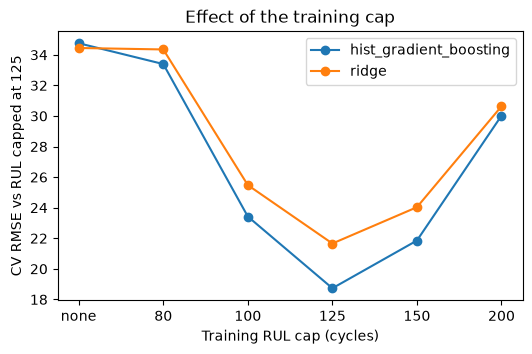

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for model_name, g in cap_table.groupby("model"):
    ax.plot(g["train_cap"].astype(str), g["rmse"], marker="o", label=model_name)
ax.set_xlabel("Training RUL cap (cycles)")
ax.set_ylabel("CV RMSE vs RUL capped at 125")
ax.set_title("Effect of the training cap")
ax.legend()
plt.show()

**Your observation:** Is there a best cap? How sensitive is the result to it? Note that this
evaluation target (capped at 125) itself favours caps near 125, so also think about what a fair
choice of target would be, and say so in your limitations.

## 5. Decision (fill in before touching the test set)

| Decision | Choice | Evidence (table / figure) |
| --- | --- | --- |
| Model carried forward | hist-gradient boosting  | Accuracy was statistically indistinguishable from random_forest,yet model speed was significantly faster. |
| Feature set | The 14 retained sensors, no operational settings| Adding the settings did not improve validation error (change of [x] cycles, below the fold spread). Removing sensors 9 and 14, or 8, 13 and 17, increased validation error, so they carry useful information.|
| RUL cap |125 |Lowest cross-validated RMSE of the caps tested (80 to 200) for gradient boosting.|

## 6. Final test-set evaluation - run ONCE, after the decisions above

Fit the chosen model on **all** training engines, then predict each test engine from its last
recorded cycle and compare with `RUL_FD001`. If you change your choices after seeing this number,
the test set is no longer an unbiased check, so do not iterate on it.

In [14]:
CHOSEN_MODEL = "hist_gradient_boosting"   # <- replace with your decision from section 5
CHOSEN_CAP = CAP
CHOSEN_FEATURES = FEATURES

model = models[CHOSEN_MODEL]()
y_train = train["RUL"].clip(upper=CHOSEN_CAP)
model.fit(train[CHOSEN_FEATURES].to_numpy(), y_train.to_numpy())

test_last = last_rows(test)                       # one row per engine, ordered by engine
pred = model.predict(test_last[CHOSEN_FEATURES].to_numpy())
true = rul_test["RUL"].to_numpy()                 # true RUL from RUL_FD001.txt

report = pd.DataFrame({
    "vs true RUL": [rmse(true, pred), mae(true, pred), nasa_score(true, pred)],
    f"vs RUL capped at {CHOSEN_CAP}": [rmse(true.clip(max=CHOSEN_CAP), pred),
                                       mae(true.clip(max=CHOSEN_CAP), pred),
                                       nasa_score(true.clip(max=CHOSEN_CAP), pred)],
}, index=["RMSE", "MAE", "NASA score"]).round(2)
report

,vs true RUL,vs RUL capped at 125
RMSE,18.72,17.78
MAE,13.42,12.35
NASA score,1031.72,999.88


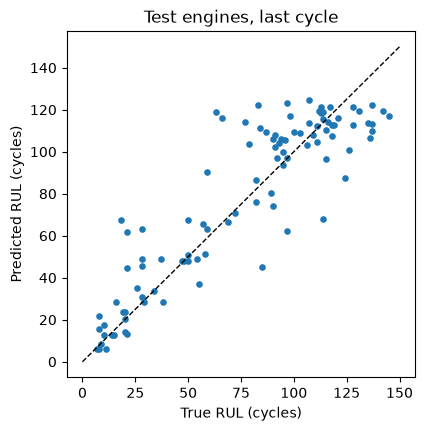

In [15]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(true, pred, s=14)
lim = [0, max(true.max(), pred.max()) + 5]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("True RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.set_title("Test engines, last cycle")
plt.show()

**Your observation:** How does the test error compare with your cross-validation error? Which engines
are worst predicted, and are the errors mostly early or late predictions? What can this validation
*not* establish (think: only 100 test points, simulated data, one operating condition)?